In [22]:
import requests
from bs4 import BeautifulSoup

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib

In [23]:
url = "http://books.toscrape.com/"

# TODO: Use `requests` to do an HTTP request to fetch data located at that URL
# TODO: Create a `BeautifulSoup` instance with that data

In [24]:
url = "http://books.toscrape.com/"

# Get the HTML of the page, then give it to the parser
response = requests.get(url)
soup = BeautifulSoup(response.content, "html.parser")

In [25]:
# Each book = one <article class="product_pod">
books_html = soup.find_all("article", class_="product_pod")
len(books_html)   # 20 books on the page

20

---

## Parsing one book

In [26]:
books_html[0]

<article class="product_pod">
<div class="image_container">
<a href="catalogue/a-light-in-the-attic_1000/index.html"><img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/></a>
</div>
<p class="star-rating Three">
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
</p>
<h3><a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">A Light in the ...</a></h3>
<div class="product_price">
<p class="price_color">£51.77</p>
<p class="instock availability">
<i class="icon-ok"></i>
    
        In stock
    
</p>
<form>
<button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">Add to basket</button>
</form>
</div>
</article>

In [27]:
# Full title is in the 'title' attribute of the <a> inside <h3> (the visible text is cut with "...")
book_title = books_html[0].find("h3").find("a").attrs["title"]
book_title

'A Light in the Attic'

now we want the price

In [28]:
# "£51.77" -> remove the currency sign -> convert to float
price_text = books_html[0].find("p", class_="price_color").text
book_price = float(price_text.replace("£", "").replace("Â", ""))
book_price

51.77

and then the rating

In [29]:
book_stars_html = books_html[0].find("p", class_="star-rating")
book_stars_html.attrs['class']   # e.g. ['star-rating', 'Three']

['star-rating', 'Three']

In [30]:
def parse_rating(rating_classes):
    # Map the word in the class list to a number
    ratings = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
    for word, value in ratings.items():
        if word in rating_classes:
            return value
    return 0   # no rating found

In [31]:
book_rating = parse_rating(books_html[0].find("p", class_="star-rating").attrs['class'])
book_rating

3

---

## Parsing all books

In [32]:
books_dict = {'Title': [], 'Price': [], 'Rating': []}

# Same code as above, but for each book of the page
for book in books_html:
    title = book.find("h3").find("a").attrs["title"]
    price = float(book.find("p", class_="price_color").text.replace("£", "").replace("Â", ""))
    rating = parse_rating(book.find("p", class_="star-rating").attrs['class'])

    books_dict['Title'].append(title)
    books_dict['Price'].append(price)
    books_dict['Rating'].append(rating)



In [33]:
len(books_dict)            # 3 keys
len(books_dict["Title"])   # 20 books

20

In [34]:
books_df = pd.DataFrame.from_dict(books_dict)
books_df

,Title,Price,Rating
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5
5,The Requiem Red,22.65,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4
7,The Coming Woman: A Novel Based on the Life of...,17.93,3
8,The Boys in the Boat: Nine Americans and Their...,22.60,4
9,The Black Maria,52.15,1


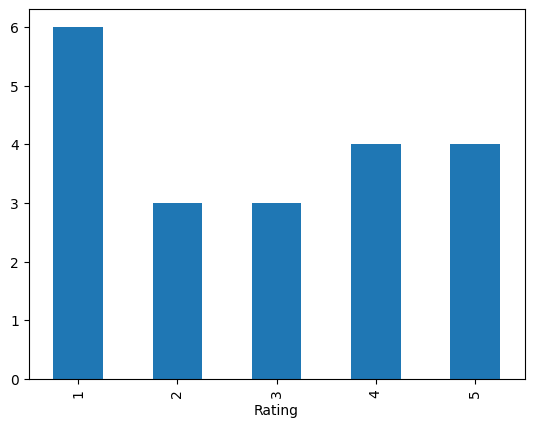

In [35]:
# Number of books per rating
books_df.groupby("Rating").count()["Title"].plot(kind="bar");

---
## lets go throught the all the pages of the catalogue

In [36]:
MAX_PAGE = 3   # test on 3 pages first, then 50
all_books_dict = {'Title': [], 'Price': [], 'Rating': []}

# Loop 1: pages / Loop 2: books on each page
for page in range(1, MAX_PAGE + 1):
    url = f"http://books.toscrape.com/catalogue/page-{page}.html"
    response = requests.get(url)
    soup = BeautifulSoup(response.content, "html.parser")

    for book in soup.find_all("article", class_="product_pod"):
        all_books_dict['Title'].append(book.find("h3").find("a").attrs["title"])
        all_books_dict['Price'].append(float(book.find("p", class_="price_color").text.replace("£", "").replace("Â", "")))
        all_books_dict['Rating'].append(parse_rating(book.find("p", class_="star-rating").attrs['class']))

In [37]:
len(all_books_dict["Title"])   # MAX_PAGE * 20 = 60

60

In [38]:
all_books_df = pd.DataFrame.from_dict(all_books_dict)
all_books_df.tail()

,Title,Price,Rating
55,The Torch Is Passed: A Harding Family Story,19.09,1
56,The Secret of Dreadwillow Carse,56.13,1
57,The Pioneer Woman Cooks: Dinnertime: Comfort C...,56.41,1
58,The Past Never Ends,56.50,4
59,The Natural History of Us (The Fine Art of Pre...,45.22,3


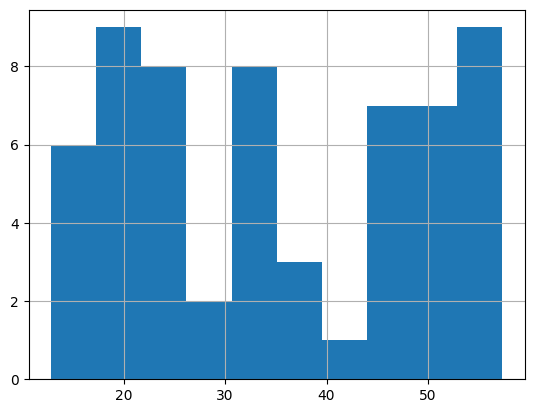

In [39]:
all_books_df["Price"].hist();

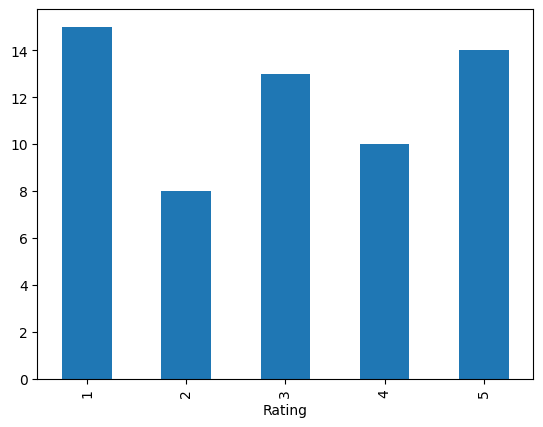

In [40]:
all_books_df.groupby("Rating").count()["Title"].plot(kind="bar");

And finally, i will save the data to not scrap all of this later on

In [41]:
# Save the results so we don't need to scrape again
all_books_df.to_csv("books.csv")
all_books_df.to_excel("books.xlsx", sheet_name="Books")